# BayesianVECM and statsmodels: same estimates, different intervals

**Audience:** analysts who already use `statsmodels` and want to know what the Bayesian fit adds.

**What this notebook does:** it fits the same VECM with `statsmodels` and with `BayesianVECM` and compares them in three steps.

| Part | Question |
|---|---|
| 1 | On one weekly dataset, do the two give the same estimates? |
| 2 | Over 30 simulated datasets, how often do the 90% intervals contain the truth? At 260 weeks and at 60 periods |
| 3 | What does each give for the return per £ of brand spend, the number a budget decision needs? |

**The short answer.**

- **Point estimates are the same.** On 260 weeks the largest gap between the two is about 0.008, against errors of up to 0.15 that both make on this sample.
- **On 260 weeks the intervals are the same too.** Both contain the truth 86% to 95% of the time, and their widths differ by a few per cent.
- **On 60 periods `statsmodels`' intervals are too narrow.** Its interval for the cointegrating vector contains the truth in 62% of datasets, and alpha in 80%. A bootstrap of the return per £ covers 70% to 87%. The posterior intervals stay at 87% to 93%.
- **Only the Bayesian fit gives an interval for the return per £ without extra code.** `statsmodels` gives a point estimate. The interval needs a bootstrap you write yourself.

The data come from `simulate_brand_data`, so the true parameters are known. Both models use the same specification throughout: rank 2, one lag of differences, a constant outside the cointegrating relation (`deterministic="co"`) and the five drivers in the same period.

In [1]:
# Sampling configuration, as in the practitioner guide.
FAST_SAMPLING = True

if FAST_SAMPLING:
    DRAWS, TUNE, CHAINS = 1000, 1000, 2
else:
    DRAWS, TUNE, CHAINS = 2000, 1000, 4

LEVEL = 0.90  # every interval in this notebook is a 90% interval
TAILS = (100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2)

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.vector_ar.vecm import VECM

from bayesian_vecm import BayesianVECM, simulate_brand_data

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)
BAYES_COLOUR, SM_COLOUR = "#2a78d6", "#eb6834"
SPEC = {"k_ar_diff": 1, "coint_rank": 2, "deterministic": "co"}

## Part 1: same data, same estimates

Both models are fitted to the default simulated data: 260 weeks, seed 14.

- `statsmodels` estimates by maximum likelihood (Johansen's method).
- `BayesianVECM` samples the posterior. Its priors are wide compared with the size of the coefficients, so the posterior mean should land close to the maximum likelihood estimate.

In [3]:
data = simulate_brand_data()
endog, exog, truth = data.endog, data.exog, data.truth
names, drivers = list(endog.columns), list(exog.columns)

sm = VECM(endog, exog=exog, **SPEC).fit()
model = BayesianVECM(**SPEC).fit(
    endog,
    exog=exog,
    draws=DRAWS,
    tune=TUNE,
    chains=CHAINS,
    target_accept=0.95,
    random_seed=42,
    progressbar=False,
)
post = model.idata_.posterior


def post_mean(name):
    return post[name].mean(("chain", "draw")).values


gamma_mean = post_mean("Gamma")
blocks = {
    # block: (statsmodels, BayesianVECM, truth)
    "alpha": (sm.alpha, post_mean("alpha"), truth.alpha),
    "beta": (sm.beta, post_mean("beta"), truth.beta),
    "Gamma": (sm.gamma, gamma_mean[:, :3], truth.gamma),
    "B": (sm.det_coef[:, 1:], post_mean("B"), truth.b),
}
rows = []
for block, (s, b, t) in blocks.items():
    rows.append(
        {
            "block": block,
            "largest gap between the two": np.abs(s - b).max(),
            "largest error, statsmodels": np.abs(s - t).max(),
            "largest error, BayesianVECM": np.abs(b - t).max(),
        }
    )
print(pd.DataFrame(rows).set_index("block").round(4))

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


       largest gap between the two  largest error, statsmodels  largest error, BayesianVECM
block                                                                                      
alpha                       0.0033                      0.0295                       0.0297
beta                        0.0008                      0.0232                       0.0225
Gamma                       0.0083                      0.1490                       0.1407
B                           0.0003                      0.0043                       0.0042


The gap between the two estimates is far smaller than the error either makes against the truth. Both read the same sample, so both make the same errors.

The table below shows the coefficients that carry the brand story. `statsmodels` puts the constant and the drivers together in `det_coef`: the constant first, then the drivers in the column order of `exog`.

In [4]:
key = [
    ("alpha", "organic_sales", "ec1", sm.alpha[0, 0], post_mean("alpha")[0, 0], truth.alpha[0, 0]),
    (
        "alpha",
        "brand_consideration",
        "ec2",
        sm.alpha[2, 1],
        post_mean("alpha")[2, 1],
        truth.alpha[2, 1],
    ),
    (
        "Gamma",
        "organic_sales",
        "d.consideration",
        sm.gamma[0, 2],
        gamma_mean[0, 2],
        truth.gamma[0, 2],
    ),
    (
        "Gamma",
        "brand_consideration",
        "d.awareness",
        sm.gamma[2, 1],
        gamma_mean[2, 1],
        truth.gamma[2, 1],
    ),
]
for j, driver in enumerate(drivers[:3]):
    key.append(
        ("B", "brand_awareness", driver, sm.det_coef[1, 1 + j], post_mean("B")[1, j], truth.b[1, j])
    )
table = pd.DataFrame(
    key, columns=["block", "equation", "regressor", "statsmodels", "BayesianVECM", "truth"]
)
print(table.round(4).to_string(index=False))

block            equation         regressor  statsmodels  BayesianVECM  truth
alpha       organic_sales               ec1      -0.2375       -0.2342 -0.240
alpha brand_consideration               ec2       0.1861        0.1839  0.180
Gamma       organic_sales   d.consideration       0.5490        0.5407  0.400
Gamma brand_consideration       d.awareness       0.2492        0.2495  0.250
    B     brand_awareness       brand_spend       0.0169        0.0170  0.018
    B     brand_awareness          pr_reach       0.0132        0.0133  0.012
    B     brand_awareness sponsorship_reach       0.0055        0.0054  0.006


**Sigma.** The innovation covariance differs by a few per cent. `statsmodels` divides the residual sum of squares by the number of observations (the maximum likelihood estimate) with no correction for the coefficients estimated. The posterior mean behaves more like the corrected estimate, which divides by observations minus coefficients per equation.

In [5]:
n_eff = sm.resid.shape[0]
n_coef = SPEC["coint_rank"] + SPEC["k_ar_diff"] * len(names) + 1 + len(drivers)  # per equation
ml = np.diag(sm.sigma_u)
print(f"Observations used: {n_eff}. Coefficients per equation: {n_coef}.")
print(
    pd.DataFrame(
        {
            "statsmodels (divide by T)": ml,
            "corrected (divide by T - coefficients)": ml * n_eff / (n_eff - n_coef),
            "BayesianVECM posterior mean": np.diag(post_mean("Sigma")),
            "truth": np.diag(truth.sigma),
        },
        index=names,
    ).map(lambda v: f"{v:.3e}")
)

Observations used: 258. Coefficients per equation: 11.
                    statsmodels (divide by T) corrected (divide by T - coefficients) BayesianVECM posterior mean  \
organic_sales                       1.702e-04                              1.778e-04                   1.800e-04   
brand_awareness                     6.796e-05                              7.099e-05                   7.180e-05   
brand_consideration                 8.809e-05                              9.201e-05                   9.290e-05   

                         truth  
organic_sales        1.800e-04  
brand_awareness      6.840e-05  
brand_consideration  8.388e-05  


**Impulse responses.** The same holds for anything built from the parameters. The table shows the response of sales to an awareness shock under a Cholesky ordering, with the variables in column order.

In [6]:
horizons = [1, 13, 52]
sm_irf = sm.irf(52).orth_irfs[:, 0, 1]
bayes_irf = model.irf(52, method="cholesky").sel(
    response_variable="organic_sales", shock_variable="brand_awareness"
)
print(
    pd.DataFrame(
        {
            "statsmodels": sm_irf[horizons],
            "BayesianVECM": bayes_irf.mean(("chain", "draw")).values[horizons],
        },
        index=pd.Index(horizons, name="week"),
    ).round(4)
)

      statsmodels  BayesianVECM
week                           
1          0.0029        0.0030
13         0.0094        0.0097
52         0.0098        0.0101


On 260 weeks the two are the same model for point estimates. The choice between them comes down to the intervals and to what can be built from the fit, which is what Parts 2 and 3 look at.

## Part 2: how often do the intervals contain the truth?

A 90% interval should contain the true value in about 90% of datasets. `tools/statsmodels_check.py` checks this on 30 seeds at two sample sizes:

- **260 weeks**, the default.
- **60 periods** of the same weekly process. This is the sample size of five years of monthly data. Keeping the weekly process means the truth is still known, which it would not be after summing weeks into months.

For each seed, parameter and model it records whether the 90% interval contains the truth.

- `statsmodels`: estimate plus or minus 1.645 asymptotic standard errors. These exist for alpha, beta, Gamma, the constant and B, but not for Sigma.
- `BayesianVECM`: the 5th and 95th percentiles of the posterior.

The script takes about 30 minutes, so this notebook reads its saved results. Run `uv run python tools/statsmodels_check.py` to rebuild them.

In [7]:
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
results = pd.read_csv(root / "tools" / "statsmodels_check_results.csv")
results = results.assign(
    bayes_in=(results.bayes_lo <= results.truth) & (results.truth <= results.bayes_hi),
    sm_in=(results.sm_lo <= results.truth) & (results.truth <= results.sm_hi),
    width_ratio=(results.bayes_hi - results.bayes_lo) / (results.sm_hi - results.sm_lo),
)
params = results[~results.block.isin(["Sigma", "return"])]
coverage = (
    params.groupby(["sample", "block"], sort=False)
    .agg(
        BayesianVECM=("bayes_in", "mean"),
        statsmodels=("sm_in", "mean"),
        width_ratio=("width_ratio", "median"),
        entries=("quantity", "nunique"),
    )
    .round(2)
)
print(f"Seeds: {results.seed.nunique()} per sample size")
print("Share of 90% intervals containing the truth, and the median width of the")
print("Bayesian interval relative to the statsmodels one")
print(coverage)

Seeds: 30 per sample size
Share of 90% intervals containing the truth, and the median width of the
Bayesian interval relative to the statsmodels one
                  BayesianVECM  statsmodels  width_ratio  entries
sample     block                                                 
260 weeks  alpha          0.88         0.86         1.03        6
           beta           0.95         0.92         1.11        2
           Gamma          0.89         0.88         1.01        9
           const          0.90         0.88         1.03        3
           B              0.88         0.86         1.03       15
60 periods alpha          0.91         0.80         1.17        6
           beta           0.90         0.62         2.24        2
           Gamma          0.89         0.86         1.07        9
           const          0.89         0.79         1.15        3
           B              0.90         0.84         1.15       15


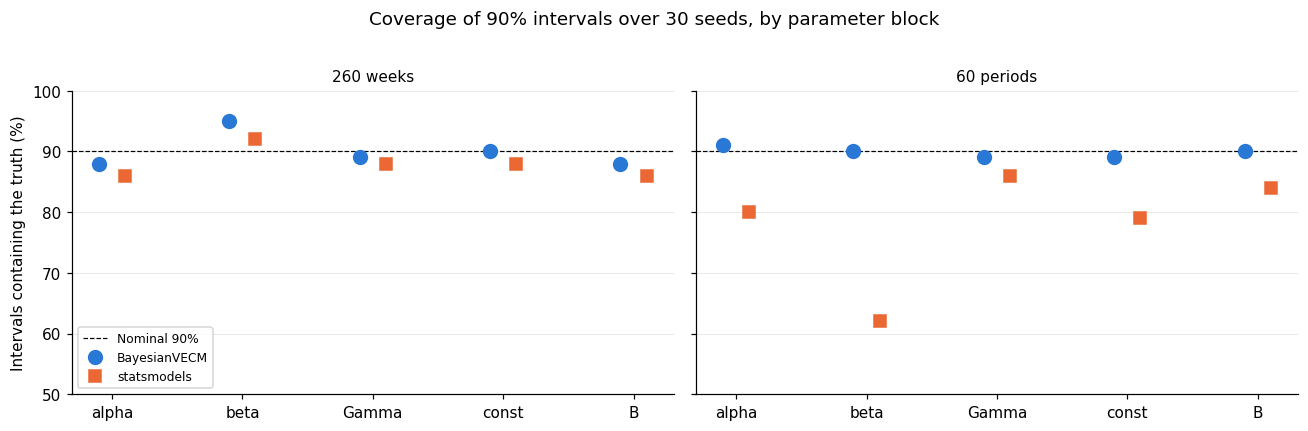

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (sample, group) in zip(axes, coverage.groupby(level="sample", sort=False), strict=True):
    group = group.droplevel("sample")
    x = np.arange(len(group))
    ax.axhline(LEVEL * 100, color="black", lw=0.8, ls="--", label="Nominal 90%")
    ax.plot(
        x - 0.1, group["BayesianVECM"] * 100, "o", ms=9, color=BAYES_COLOUR, label="BayesianVECM"
    )
    ax.plot(x + 0.1, group["statsmodels"] * 100, "s", ms=8, color=SM_COLOUR, label="statsmodels")
    ax.grid(axis="y", color="0.9", lw=0.6)
    ax.set_xticks(x, group.index)
    ax.set_ylim(50, 100)
    ax.set_title(sample, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Intervals containing the truth (%)")
axes[0].legend(fontsize=8, loc="lower left")
plt.suptitle("Coverage of 90% intervals over 30 seeds, by parameter block", y=1.02)
plt.tight_layout()
plt.show()

**At 260 weeks** both models are close to the nominal 90%, and their intervals are within a few per cent of each other in width. With 30 seeds a share like 88% carries a few points of noise, so 86% against 88% is not a difference.

**At 60 periods** the asymptotic intervals of `statsmodels` cover too little:

- The cointegrating vector `beta` is the worst, at 62%. Its standard error shrinks with the sample size faster than the others do, which is right in the limit and too optimistic at 60 observations. In seed 1 the maximum likelihood estimate of one entry is -5.5 against a truth of -1.25, with an interval of [-6.9, -4.0].
- alpha and the constant fall to about 80%, and B to 84%.
- The posterior intervals stay at 89% to 91% in every block. They are 7% to 17% wider than the `statsmodels` intervals, and 2.2 times wider for `beta`. The extra width is what it takes to reach the stated coverage.

The priors here are the package defaults, which are wide. The coverage comes from the posterior describing the sampling uncertainty, not from prior information about the truth.

## Part 3: the return per £ of brand spend

A budget decision does not need alpha or Gamma. It needs the return: the extra revenue from one more £ of brand spend, summed over a window. The practitioner guide (§9b) gets it from `model.exog_irf()`:

- push a one-week, one-unit rise in brand spend through the fitted system;
- convert the log change in sales each week into revenue at recent average weekly sales;
- sum over 1 year and 5 years and divide by the cost of the unit.

The return is a non-linear function of every parameter. `statsmodels` gives a point estimate for it but no interval. The usual route to an interval is a bootstrap, which you write yourself: rebuild the data many times from the fitted model with resampled residuals, refit each one and recompute the return. The Bayesian fit gives the interval directly: compute the return for each posterior draw.

The units follow the practitioner guide. One `brand_spend` unit costs £1,000.

In [9]:
COST_GBP = 1_000.0
WINDOWS = {"1 year": 52, "5 years": 260}
N_BOOT = 499


def sales_returns(alpha, beta, gamma, b, steps=260):
    # Summed sales return to a one-week, one-unit rise in brand spend, in units of weekly sales.
    # Inputs carry a leading draw dimension; uses the same recursion as the DGP.
    n_draws, n_vars = alpha.shape[0], alpha.shape[1]
    pi = np.einsum("dir,djr->dij", alpha, beta[:, :n_vars])
    gamma = gamma[:, :, :n_vars]  # drop the constant column of the posterior Gamma
    level, growth = np.zeros((n_draws, n_vars)), np.zeros((n_draws, n_vars))
    path = np.zeros((n_draws, steps))
    for h in range(steps):
        growth = np.einsum("dij,dj->di", pi, level) + np.einsum("dij,dj->di", gamma, growth)
        if h == 0:
            growth = growth + b[:, :, 0]  # brand_spend is the first driver
        level = level + growth
        path[:, h] = level[:, 0]  # organic_sales
    path = np.expm1(path)
    return {label: path[:, :weeks].sum(axis=1) for label, weeks in WINDOWS.items()}


def bootstrap_returns(res, endog, exog, seed):
    # Residual bootstrap: resample residual rows, rebuild the data, refit, recompute.
    y, x = endog.to_numpy(), exog.to_numpy()
    n_obs = len(y)
    pi = res.alpha @ res.beta.T
    det = np.column_stack([np.ones(n_obs), x])  # statsmodels order: constant, then drivers
    resid = res.resid - res.resid.mean(axis=0)
    rng = np.random.default_rng(seed)
    paths = np.repeat(y[None], N_BOOT, axis=0)
    shocks = resid[rng.integers(0, len(resid), size=(N_BOOT, len(resid)))]
    for t in range(2, n_obs):
        prev, prev2 = paths[:, t - 1], paths[:, t - 2]
        paths[:, t] = (
            prev
            + prev @ pi.T
            + (prev - prev2) @ res.gamma.T
            + det[t] @ res.det_coef.T
            + shocks[:, t - 2]
        )
    fits = [VECM(p, exog=x, **SPEC).fit() for p in paths]
    return sales_returns(
        np.stack([f.alpha for f in fits]),
        np.stack([f.beta for f in fits]),
        np.stack([f.gamma for f in fits]),
        np.stack([f.det_coef[:, 1:] for f in fits]),
    )


def draws(model, name):
    values = model.idata_.posterior[name].values
    return values.reshape(-1, *values.shape[2:])

Both models are fitted at both sample sizes on seed 14. The 260-week fits are the ones from Part 1.

In [10]:
short = simulate_brand_data(n_obs=60)
sm_short = VECM(short.endog, exog=short.exog, **SPEC).fit()
model_short = BayesianVECM(**SPEC).fit(
    short.endog,
    exog=short.exog,
    draws=DRAWS,
    tune=TUNE,
    chains=CHAINS,
    target_accept=0.95,
    random_seed=42,
    progressbar=False,
)

true_ret = sales_returns(truth.alpha[None], truth.beta[None], truth.gamma[None], truth.b[None])
recent_sales = float(np.exp(endog["organic_sales"].iloc[-52:]).mean())
per_gbp = recent_sales / COST_GBP  # turns a return in weekly-sales units into £ per £1

per_sample = {}
rows = []
for label, sm_fit, bayes_fit, d in [
    ("260 weeks", sm, model, data),
    ("60 periods", sm_short, model_short, short),
]:
    point = sales_returns(
        sm_fit.alpha[None], sm_fit.beta[None], sm_fit.gamma[None], sm_fit.det_coef[None, :, 1:]
    )
    boot = bootstrap_returns(sm_fit, d.endog, d.exog, seed=0)
    post_ret = sales_returns(
        draws(bayes_fit, "alpha"),
        draws(bayes_fit, "beta"),
        draws(bayes_fit, "Gamma"),
        draws(bayes_fit, "B"),
    )
    per_sample[label] = (boot, post_ret)
    for window in WINDOWS:
        b_lo, b_hi = np.percentile(boot[window], TAILS) * per_gbp
        p_lo, p_hi = np.percentile(post_ret[window], TAILS) * per_gbp
        rows.append(
            {
                "sample": label,
                "window": window,
                "truth": true_ret[window][0] * per_gbp,
                "statsmodels": point[window][0] * per_gbp,
                "bootstrap 90%": f"[{b_lo:.1f}, {b_hi:.1f}]",
                "BayesianVECM (median)": np.median(post_ret[window]) * per_gbp,
                "posterior 90%": f"[{p_lo:.1f}, {p_hi:.1f}]",
            }
        )
print("Revenue back per £1 of brand spend for one week (£)")
print(pd.DataFrame(rows).round(2).to_string(index=False))

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


Revenue back per £1 of brand spend for one week (£)
    sample  window  truth  statsmodels bootstrap 90%  BayesianVECM (median) posterior 90%
 260 weeks  1 year   1.83         1.99    [1.4, 2.6]                   2.00    [1.4, 2.6]
 260 weeks 5 years  10.02        11.24   [8.3, 14.2]                  11.29   [8.2, 14.7]
60 periods  1 year   1.83         1.89    [0.8, 3.1]                   1.72    [0.4, 3.3]
60 periods 5 years  10.02         9.83   [3.7, 16.3]                   8.87   [1.3, 17.4]


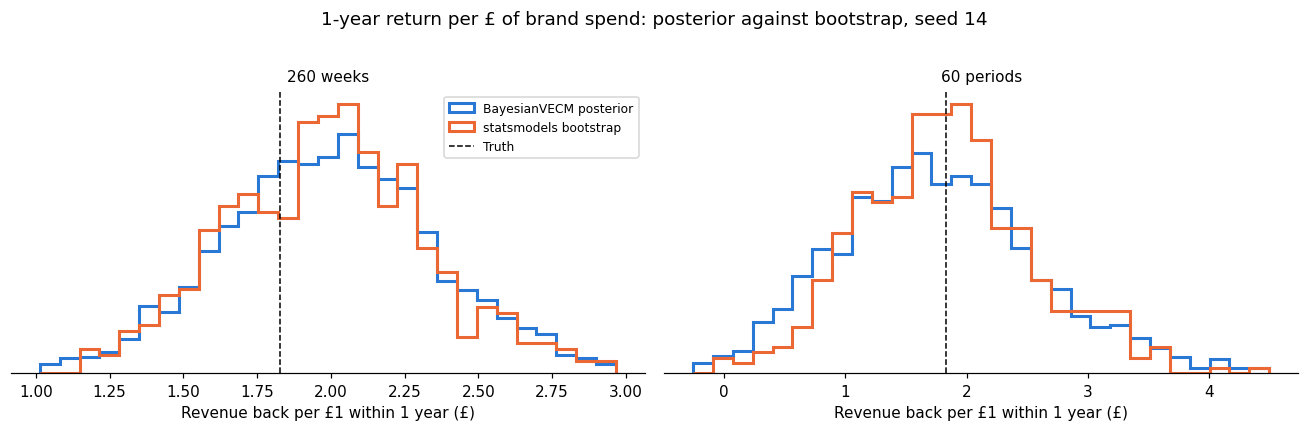

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (label, (boot, post_ret)) in zip(axes, per_sample.items(), strict=True):
    b, p = boot["1 year"] * per_gbp, post_ret["1 year"] * per_gbp
    edges = np.linspace(*np.percentile(np.concatenate([b, p]), [0.5, 99.5]), 30)
    ax.hist(
        p,
        bins=edges,
        density=True,
        histtype="step",
        lw=2,
        color=BAYES_COLOUR,
        label="BayesianVECM posterior",
    )
    ax.hist(
        b,
        bins=edges,
        density=True,
        histtype="step",
        lw=2,
        color=SM_COLOUR,
        label="statsmodels bootstrap",
    )
    ax.axvline(true_ret["1 year"][0] * per_gbp, color="black", lw=1, ls="--", label="Truth")
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Revenue back per £1 within 1 year (£)")
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
axes[0].legend(fontsize=8)
plt.suptitle("1-year return per £ of brand spend: posterior against bootstrap, seed 14", y=1.02)
plt.tight_layout()
plt.show()

On 260 weeks the posterior and the bootstrap tell the same story: brand spend returns about £2 per £1 within a year, with a 90% interval of about £1.40 to £2.60. On 60 periods both spread out: £0.80 to £3.10 from the bootstrap and £0.40 to £3.30 from the posterior, which has the longer lower tail.

One seed says little about calibration. The sweep in Part 2 also recorded the returns for all three channels:

In [12]:
ret = results[results.block == "return"].copy()
ret["window"] = ret.quantity.str.extract(r"return (\d years?)")[0]
ret["channel"] = ret.quantity.str.split(": ").str[1]
ret_cover = (
    ret.groupby(["sample", "window", "channel"], sort=False)
    .agg(
        truth=("truth", "first"),
        BayesianVECM=("bayes_in", "mean"),
        bootstrap=("sm_in", "mean"),
        width_ratio=("width_ratio", "median"),
    )
    .round(2)
)
print("Share of 90% intervals containing the true return (truth in units of weekly sales),")
print("and the median width of the posterior interval relative to the bootstrap one")
print(ret_cover)

Share of 90% intervals containing the true return (truth in units of weekly sales),
and the median width of the posterior interval relative to the bootstrap one
                                      truth  BayesianVECM  bootstrap  width_ratio
sample     window  channel                                                       
260 weeks  1 year  brand_spend         1.04          0.97       0.90         1.07
           5 years brand_spend         5.72          0.93       0.90         1.08
           1 year  pr_reach            0.69          0.87       0.87         1.06
           5 years pr_reach            3.80          0.90       0.83         1.08
           1 year  sponsorship_reach   0.35          0.87       0.87         1.04
           5 years sponsorship_reach   1.89          0.90       0.90         1.05
60 periods 1 year  brand_spend         1.04          0.87       0.80         1.32
           5 years brand_spend         5.72          0.87       0.70         1.37
           1 year  

- **260 weeks:** the posterior intervals contain the true return 87% to 97% of the time, the bootstrap intervals 83% to 90%. The posterior intervals are 4% to 8% wider.
- **60 periods:** the bootstrap drops to 70% to 87%, with the worst case the 5-year return of brand spend. The posterior holds 87% to 93%, with intervals about a third wider.
- Both point estimates of the brand spend return are too low at 60 periods. Across seeds the posterior median averages 0.80 and the `statsmodels` estimate 0.87, against a truth of 1.04 (from `tools/statsmodels_check.py`). The posterior interval still covers the truth because it is wide enough to.
- The bootstrap here is the plain residual bootstrap with percentile intervals. Refinements such as bias correction may close part of the gap, at the cost of more code.

## What this means

- **For point estimates, `statsmodels` is enough.** It gives the same numbers in milliseconds, against about 20 seconds of sampling.
- **On five years of weekly data the intervals agree too.** The Bayesian fit then wins on convenience: every derived quantity, such as the return per £, a counterfactual path or `exog_irf`, gets an interval from the same draws, with no bootstrap to write.
- **On short samples the Bayesian intervals are the honest ones.** At 60 periods, the length of five years of monthly data, the asymptotic intervals and the plain bootstrap claim more precision than the data hold. The posterior keeps close to the stated coverage. This is the main case for the Bayesian fit, and short samples are also where informative priors would help most.

**Not tested here:**

- Summing weeks into months. That changes the model itself, and it affects both fits the same way. `docs/granger_pretest.md` covers its effect on the pretest.
- Informative priors. All fits use the defaults.
- A misspecified model, for example the wrong rank or missing lags.